# Sales Prediction Using Python
**Oasis Infobyte Internship (Data Science) - Task 5**

**Objective:** In this project I build a regression model that predicts product sales from the money spent on advertising in three media channels: TV, Radio and Newspaper. I also want to find out which channel has the biggest impact on sales.

## 1. Importing Libraries
I import pandas and numpy for the data, matplotlib and seaborn for the charts, and scikit-learn for the models and the evaluation metrics.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 70

## 2. Loading the Dataset
I am using the classic `Advertising.csv` dataset from Kaggle. It has 200 rows, with the advertising spend (in thousands of dollars) for TV, Radio and Newspaper, and the Sales (in thousands of units). The file has an extra unnamed index column which I don't need, so I drop it.

In [2]:
df = pd.read_csv('Advertising.csv')
df = df.drop(columns=df.columns[0])   # drop the unnamed index column
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 3. Exploratory Data Analysis (EDA)
First I check the size, the data types, missing values, duplicates and the basic statistics.

In [3]:
print('Shape:', df.shape)
print('\nData types:')
print(df.dtypes)
print('\nNull values:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

Shape: (200, 4)

Data types:
TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

Null values:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows: 0


In [4]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


**What I see:** there are 200 rows and 4 numeric columns with no missing values and no duplicates, so the data is already clean. TV has the largest spending range (from under 1 to about 300), Radio goes up to about 50, and Newspaper goes up to about 114. The average Sales is around 14.

### 3.1 Pairplot of all features

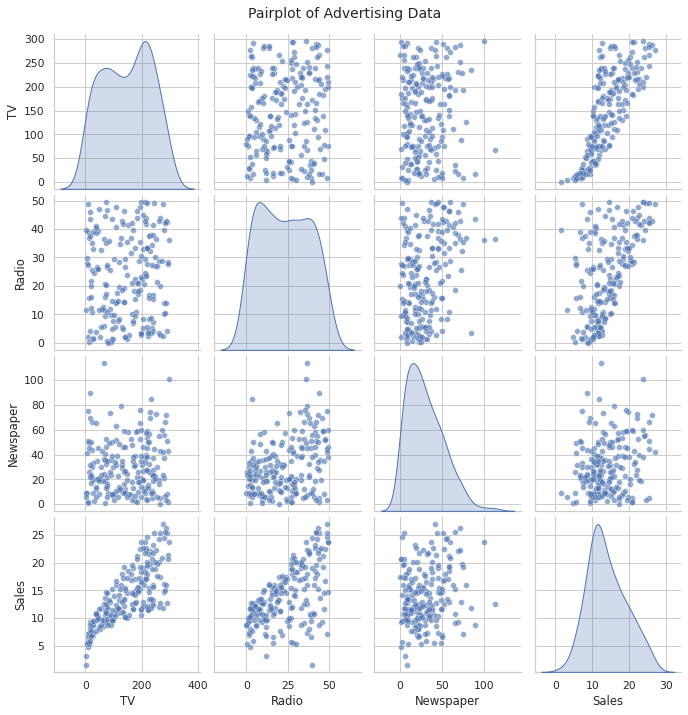

In [5]:
sns.pairplot(df, diag_kind='kde', plot_kws={'alpha': 0.6})
plt.suptitle('Pairplot of Advertising Data', y=1.02)
plt.show()

**What I see:** the TV vs Sales plot shows a very clear, almost straight upward line, so more TV spend means more sales. Radio vs Sales also goes up but is more spread out. Newspaper vs Sales looks like a random cloud, so there is little relationship.

### 3.2 Sales vs each advertising channel

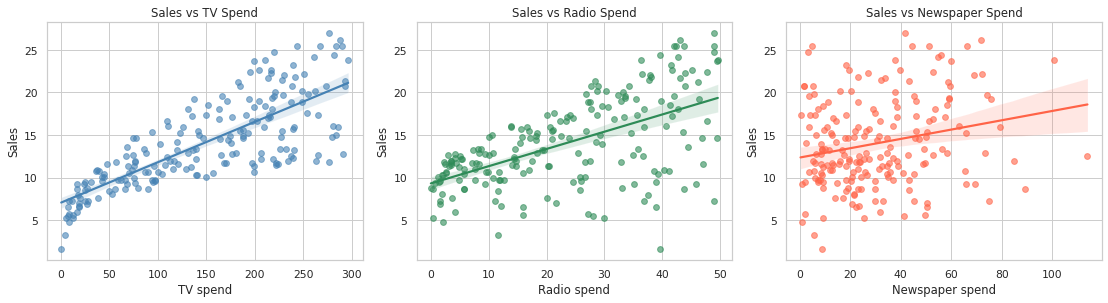

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, color in zip(axes, ['TV', 'Radio', 'Newspaper'], ['steelblue', 'seagreen', 'tomato']):
    sns.regplot(data=df, x=col, y='Sales', ax=ax, color=color, scatter_kws={'alpha': 0.6})
    ax.set_title(f'Sales vs {col} Spend')
    ax.set_xlabel(f'{col} spend')
plt.tight_layout()
plt.show()

**What I see:** the TV line is steep and the points stay close to it, so TV spend is a strong predictor. Radio has a positive trend with more scatter. The Newspaper line is almost flat and the points are all over the place, so newspaper spend does very little to explain sales.

### 3.3 Correlation heatmap

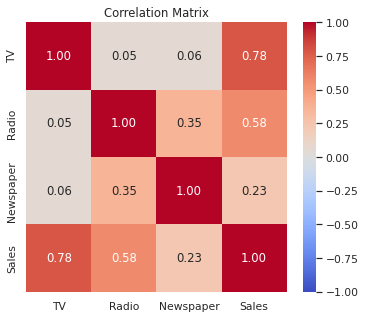

Sales        1.000000
TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64


In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()
print(df.corr()['Sales'].sort_values(ascending=False))

**What I see:** Sales has a strong correlation with TV (about 0.78), a moderate one with Radio (about 0.58) and a weak one with Newspaper (about 0.23). TV has almost no correlation with Radio or Newspaper (about 0.05), so it brings its own separate information. Radio and Newspaper are correlated with each other (about 0.35), which means newspaper spending tends to go up when radio spending goes up. So Newspaper's small link with sales may partly come from Radio.

## 4. Train/Test Split
I separate the features (TV, Radio, Newspaper) from the target (Sales) and split the data 80% for training and 20% for testing.

In [8]:
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print('Training samples:', X_train.shape[0])
print('Test samples:', X_test.shape[0])

Training samples: 160
Test samples: 40


## 5. Training the Models
I train three models:
1. **Linear Regression** as the baseline
2. **Polynomial Regression (degree 2)**, which can capture curved relationships and interactions between channels
3. **Random Forest Regressor**, a stronger model that does not assume a straight-line relationship

In [9]:
models = {
    'Linear Regression': LinearRegression(),
    'Polynomial Regression (deg 2)': make_pipeline(PolynomialFeatures(degree=2, include_bias=False),
                                                  LinearRegression()),
    'Random Forest': RandomForestRegressor(n_estimators=200, random_state=42),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(name, 'trained')

Linear Regression trained
Polynomial Regression (deg 2) trained


Random Forest trained


## 6. Evaluating the Models
I use three metrics:
- **MAE** (Mean Absolute Error): the average size of the error, in the same units as Sales
- **RMSE** (Root Mean Squared Error): similar to MAE but punishes big errors more
- **R² score**: how much of the variation in sales the model explains (1.0 is perfect)

In [10]:
rows = []
for name, y_pred in predictions.items():
    rows.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred),
    })
results = pd.DataFrame(rows).set_index('Model').round(4)
results

,MAE,RMSE,R2
Model,,,
Linear Regression,1.4608,1.7816,0.8994
Polynomial Regression (deg 2),0.5262,0.6426,0.9869
Random Forest,0.6287,0.7572,0.9818


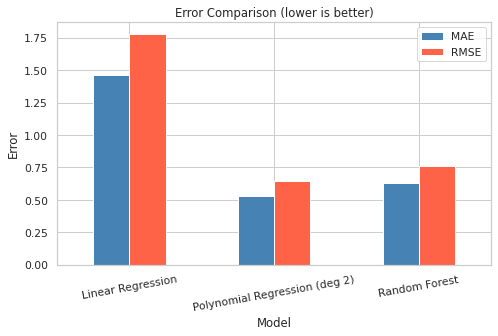

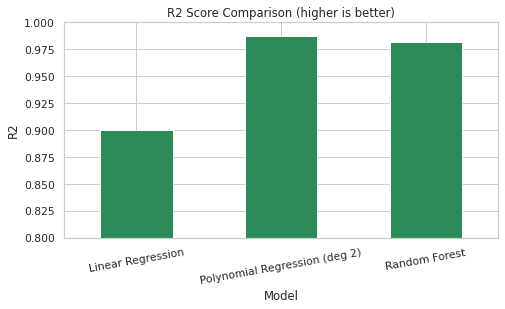

In [11]:
results[['MAE', 'RMSE']].plot(kind='bar', figsize=(8, 4.5), rot=10, color=['steelblue', 'tomato'])
plt.title('Error Comparison (lower is better)')
plt.ylabel('Error')
plt.show()

results['R2'].plot(kind='bar', figsize=(8, 4), rot=10, color='seagreen', ylim=(0.8, 1.0))
plt.title('R2 Score Comparison (higher is better)')
plt.ylabel('R2')
plt.show()

## 7. Residual Plot for the Best Model
A residual is the difference between the actual and the predicted value. If a model is good, the residuals should be randomly scattered around zero with no pattern. If I see a curve or a funnel shape, it means the model is making systematic errors.

Best model by R2: Polynomial Regression (deg 2)


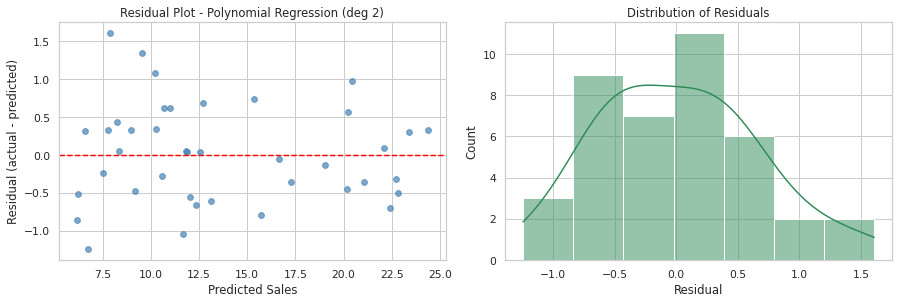

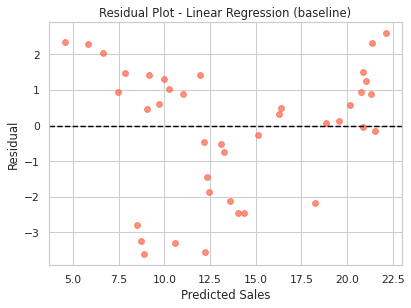

In [12]:
best_name = results['R2'].idxmax()
best_pred = predictions[best_name]
residuals = y_test - best_pred
print('Best model by R2:', best_name)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(best_pred, residuals, alpha=0.7, color='steelblue')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted Sales')
axes[0].set_ylabel('Residual (actual - predicted)')
axes[0].set_title(f'Residual Plot - {best_name}')

sns.histplot(residuals, kde=True, ax=axes[1], color='seagreen')
axes[1].set_title('Distribution of Residuals')
axes[1].set_xlabel('Residual')
plt.tight_layout()
plt.show()

# Also the residual plot of the baseline Linear Regression for comparison
lin_resid = y_test - predictions['Linear Regression']
plt.figure(figsize=(6.5, 4.5))
plt.scatter(predictions['Linear Regression'], lin_resid, alpha=0.7, color='tomato')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Predicted Sales')
plt.ylabel('Residual')
plt.title('Residual Plot - Linear Regression (baseline)')
plt.show()

**What I see:** for the best model (Polynomial Regression) the residuals are scattered randomly around zero. They have no clear curve or funnel shape and the histogram is roughly bell-shaped and centred near zero, so the errors look random and not systematic. For the baseline Linear Regression the residual plot is different: the residuals are mostly positive for low predictions, negative for medium predictions and positive again for high predictions. That U-shaped pattern means a straight line is missing something, which is the curved effect and the interaction between channels. This is the reason the polynomial model does so much better.

## 8. Which Advertising Channel Has the Highest Impact?
I answer this in two ways. First, the coefficients of a Linear Regression trained on **standardised** features (so they can be fairly compared, since TV, Radio and Newspaper have different scales). Second, the feature importance from the Random Forest.

Standardised Linear Regression coefficients:
TV           3.764
Radio        2.792
Newspaper    0.056
dtype: float64

Original-scale coefficients (sales change per 1 unit extra spend):
TV           0.0447
Radio        0.1892
Newspaper    0.0028
dtype: float64


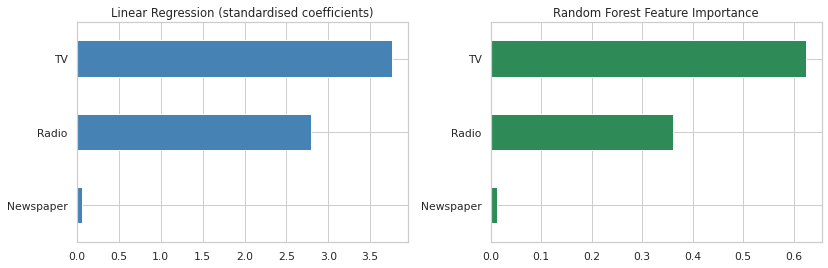


Random Forest importance:
TV           0.625
Radio        0.362
Newspaper    0.013
dtype: float64


In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
lin_scaled = LinearRegression().fit(X_train_scaled, y_train)

coef = pd.Series(lin_scaled.coef_, index=X.columns)
print('Standardised Linear Regression coefficients:')
print(coef.sort_values(ascending=False).round(3))

# Coefficients on the original scale (effect of 1 extra unit of spend)
lin = models['Linear Regression']
print('\nOriginal-scale coefficients (sales change per 1 unit extra spend):')
print(pd.Series(lin.coef_, index=X.columns).round(4))

rf_imp = pd.Series(models['Random Forest'].feature_importances_, index=X.columns)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
coef.sort_values().plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Linear Regression (standardised coefficients)')
rf_imp.sort_values().plot(kind='barh', ax=axes[1], color='seagreen')
axes[1].set_title('Random Forest Feature Importance')
plt.tight_layout()
plt.show()
print('\nRandom Forest importance:')
print(rf_imp.sort_values(ascending=False).round(3))

**What I see:** both methods agree that **TV has the highest overall impact on sales**. In the standardised Linear Regression, TV has the largest coefficient (about 3.76), followed by Radio (about 2.79) and Newspaper, which is almost zero (about 0.06). The Random Forest says the same thing: TV is about 62% of the importance, Radio about 36% and Newspaper only about 1%.

One more interesting point from the original-scale coefficients: one extra unit of spend on **Radio** raises sales by about 0.19, compared to about 0.045 for TV. So Radio is more effective per unit of money, but TV is the biggest driver overall because the TV budgets are much larger and vary more. Newspaper spend has almost no effect.

## 9. Best Model and Conclusion
I trained three models and compared them on the test set:

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression (baseline) | 1.46 | 1.78 | 0.899 |
| **Polynomial Regression (degree 2)** | **0.53** | **0.64** | **0.987** |
| Random Forest | 0.63 | 0.76 | 0.982 |

The baseline Linear Regression is already decent with an R² of about 0.90, but both other models are clearly better. **Polynomial Regression (degree 2) is the best model**: it has the lowest MAE and RMSE and the highest R² (about 0.987), which means it explains almost 99% of the variation in sales. Its predictions are off by only about 0.5 units on average. Random Forest is a close second.

The polynomial model wins because the relationship is not perfectly a straight line. The channels work together (for example TV and Radio together give a bigger boost than each alone), and the polynomial terms capture that. Its random-looking residual plot also supports this choice.

**Business insight:** TV is the most important channel and Radio is second, while Newspaper adds almost nothing. If a company wants to improve sales, it should focus the budget on TV and Radio and cut down on Newspaper.

**Limitations:** the dataset has only 200 rows and the test set only 40, so the scores can change a little with a different split. Also, this shows correlation in this data and not guaranteed cause and effect.

## 10. Predicting Sales for a New Budget
Finally I use the best model to predict sales for a few made-up advertising budgets.

In [14]:
best_model = models[best_name]
new_budgets = pd.DataFrame({
    'TV': [150, 50, 250],
    'Radio': [20, 40, 10],
    'Newspaper': [30, 30, 30],
})
new_budgets['Predicted Sales'] = best_model.predict(new_budgets[['TV', 'Radio', 'Newspaper']]).round(2)
print('Best model:', best_name)
new_budgets

Best model: Polynomial Regression (deg 2)


,TV,Radio,Newspaper,Predicted Sales
0,150,20,30,14.21
1,50,40,30,10.82
2,250,10,30,14.02
